# Modularity on the Karate Club Graph

**Course:** DSC212 — Graph Theory  
**Topic:** Spectral community detection using the modularity matrix

## Objective

This assignment applies recursive spectral partitioning to Zachary's Karate Club graph. We construct the global modularity matrix, repeatedly split communities using the leading eigenvector of the corresponding restricted block, and examine how node-level network metrics evolve as the communities become smaller.

The implementation is self-contained: all functions are defined in this notebook, and the visualisations are displayed inline.

## 1. Import libraries

We use NetworkX for graph operations, NumPy for matrix and eigenvalue computations, Matplotlib for visualisation, and Pandas to organise the metric history.

In [1]:
import os
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from IPython.display import display

OUTPUT_DIR = "output"
COMMUNITY_DIR = os.path.join(OUTPUT_DIR, "communities")
METRIC_DIR = os.path.join(OUTPUT_DIR, "metrics")

os.makedirs(COMMUNITY_DIR, exist_ok=True)
os.makedirs(METRIC_DIR, exist_ok=True)

plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["figure.dpi"] = 110

## 2. Load the Karate Club graph

The Zachary Karate Club graph contains 34 nodes and 78 edges. Each node represents a club member and each edge represents a friendship tie.

Karate Club Graph
-----------------
Number of nodes: 34
Number of edges: 78


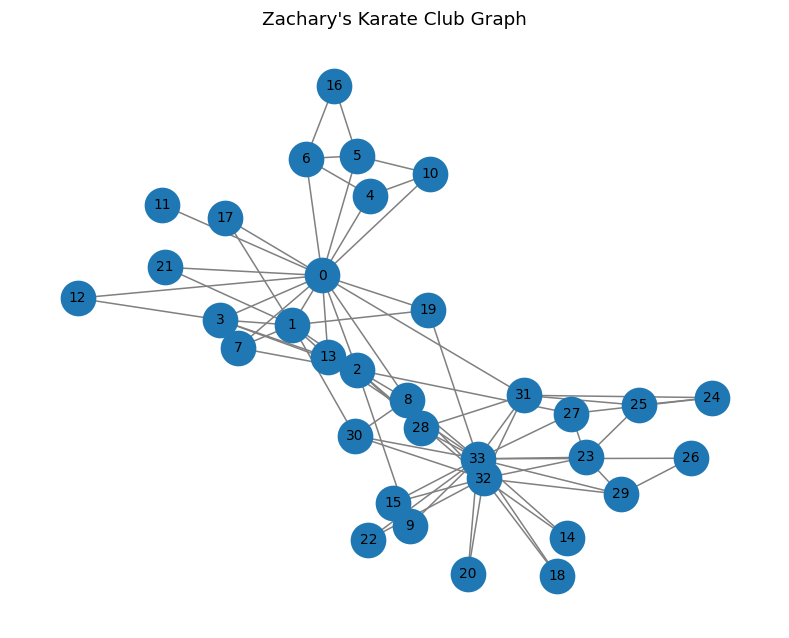

In [2]:
G = nx.karate_club_graph()
nodes = list(G.nodes())

print("Karate Club Graph")
print("-----------------")
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

assert G.number_of_nodes() == 34
assert G.number_of_edges() == 78

pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(9, 7))
nx.draw_networkx(
    G, pos,
    with_labels=True,
    node_size=500,
    font_size=9,
    edge_color="gray"
)
plt.title("Zachary's Karate Club Graph")
plt.axis("off")
plt.show()

## 3. Construct the global modularity matrix

For an undirected graph, the modularity matrix is

\[
B_{ij} = A_{ij} - \frac{k_i k_j}{2m},
\]

where \(A\) is the adjacency matrix, \(k_i\) is the degree of node \(i\), and \(m\) is the number of edges.

We construct this matrix once. During recursive partitioning, each community uses the corresponding block of this **original global matrix**.

In [3]:
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)
degrees = A.sum(axis=1)
m = G.number_of_edges()

B = A - np.outer(degrees, degrees) / (2 * m)

print("Modularity matrix shape:", B.shape)
print("Symmetric:", np.allclose(B, B.T))
print("Row sums are zero:", np.allclose(B.sum(axis=1), 0, atol=1e-10))

assert B.shape == (34, 34)
assert np.allclose(B, B.T)
assert np.allclose(B.sum(axis=1), 0, atol=1e-10)

Modularity matrix shape: (34, 34)
Symmetric: True
Row sums are zero: True


## 4. Spectral community detection

For a community \(C\), we extract the block \(B(C)\) from the global modularity matrix. We find its largest eigenvalue and corresponding eigenvector. If the largest eigenvalue is positive, the signs of the eigenvector entries define the two candidate subcommunities.

The process is applied recursively to each resulting community. Partitioning stops for a community when its largest eigenvalue is non-positive (within a small numerical tolerance), or when the sign partition would produce an empty group.

In [4]:
def spectral_split(community, B, nodes, tolerance=1e-10):
    # Preserve the node order used when constructing the global matrix.
    community = set(community)
    indices = [i for i, node in enumerate(nodes) if node in community]

    # Restrict the original global modularity matrix to this community.
    Bc = B[np.ix_(indices, indices)]

    eigenvalues, eigenvectors = np.linalg.eigh(Bc)
    leading_index = np.argmax(eigenvalues)

    largest_eigenvalue = float(eigenvalues[leading_index])
    leading_eigenvector = eigenvectors[:, leading_index]

    if largest_eigenvalue <= tolerance:
        return None

    community_1 = set()
    community_2 = set()

    for node, value in zip([nodes[i] for i in indices], leading_eigenvector):
        if value > 0:
            community_1.add(node)
        else:
            community_2.add(node)

    if not community_1 or not community_2:
        return None

    return community_1, community_2, largest_eigenvalue


def recursive_partition(G, B):
    nodes = list(G.nodes())
    communities = [set(nodes)]
    snapshots = []

    def split(community):
        result = spectral_split(community, B, nodes)
        if result is None:
            return

        C1, C2, eigenvalue = result
        communities.remove(community)
        communities.extend([C1, C2])

        snapshots.append({
            "communities": [c.copy() for c in communities],
            "eigenvalue": eigenvalue
        })

        print(
            f"Split {len(snapshots)} | "
            f"leading eigenvalue = {eigenvalue:.6f} | "
            f"communities = {len(communities)}"
        )

        split(C1)
        split(C2)

    split(set(nodes))
    return communities, snapshots

## 5. Run recursive partitioning

We now apply the recursive procedure to the graph. Each snapshot records the community assignment immediately after a successful split.

In [5]:
final_communities, snapshots = recursive_partition(G, B)

# Check that the final communities form a disjoint partition of all graph nodes.
all_final_nodes = set().union(*final_communities)
assert all_final_nodes == set(nodes)
assert sum(len(c) for c in final_communities) == len(nodes)

print("\nFinal communities:")
for i, community in enumerate(final_communities, start=1):
    print(f"Community {i}: {sorted(community)}")

print("\nTotal successful splits:", len(snapshots))
print("Number of final communities:", len(final_communities))

Split 1 | leading eigenvalue = 4.977080 | communities = 2
Split 2 | leading eigenvalue = 2.944129 | communities = 3
Split 3 | leading eigenvalue = 2.147993 | communities = 4
Split 4 | leading eigenvalue = 2.504088 | communities = 5

Final communities:
Community 1: [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
Community 2: [11]
Community 3: [4, 5, 6, 10, 16]
Community 4: [24, 25, 27, 28, 31]
Community 5: [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]

Total successful splits: 4
Number of final communities: 5


## 6. Visualise the communities after each split

We use the same spring-layout coordinates for every snapshot so that changes in colour show the changing community assignments rather than movement in the graph layout.

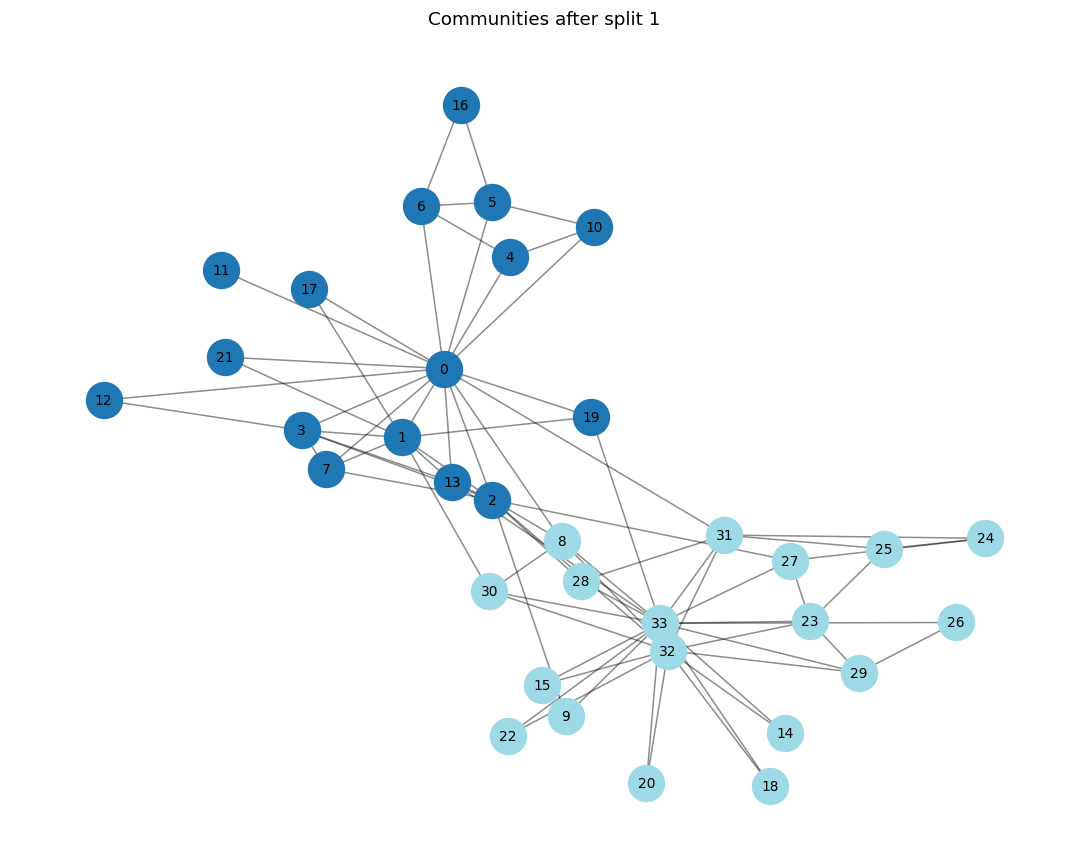

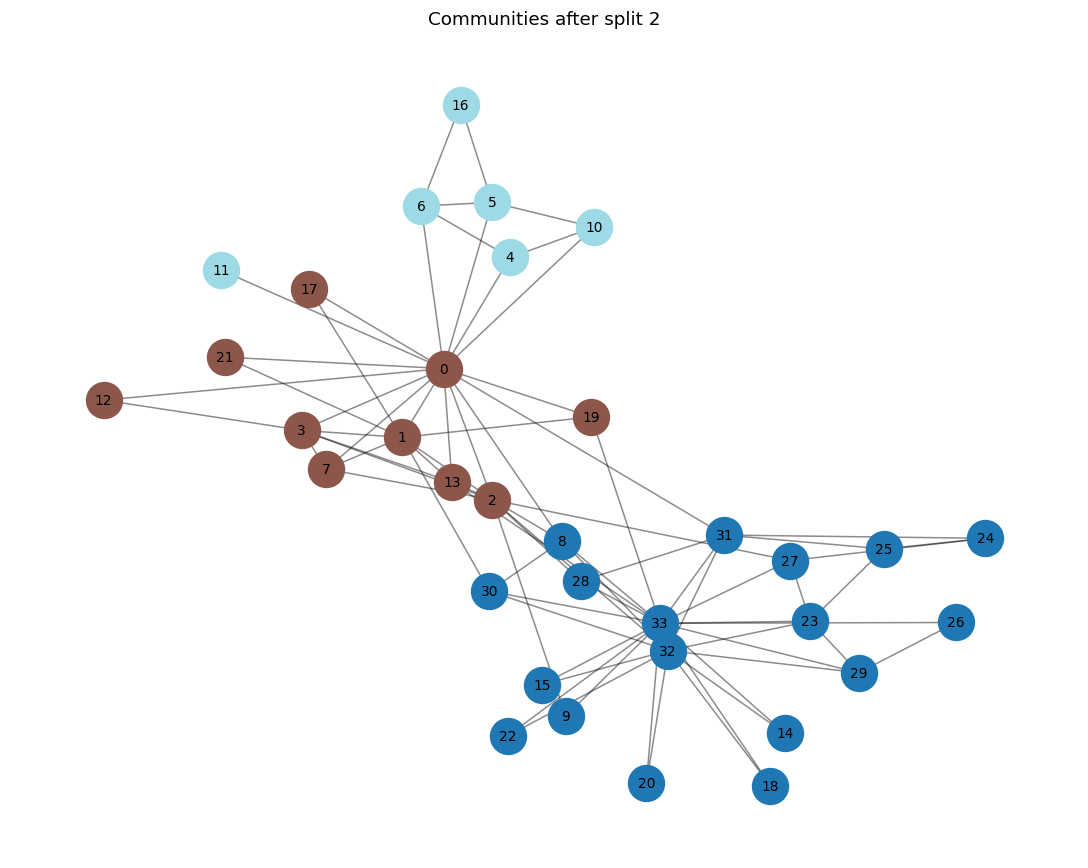

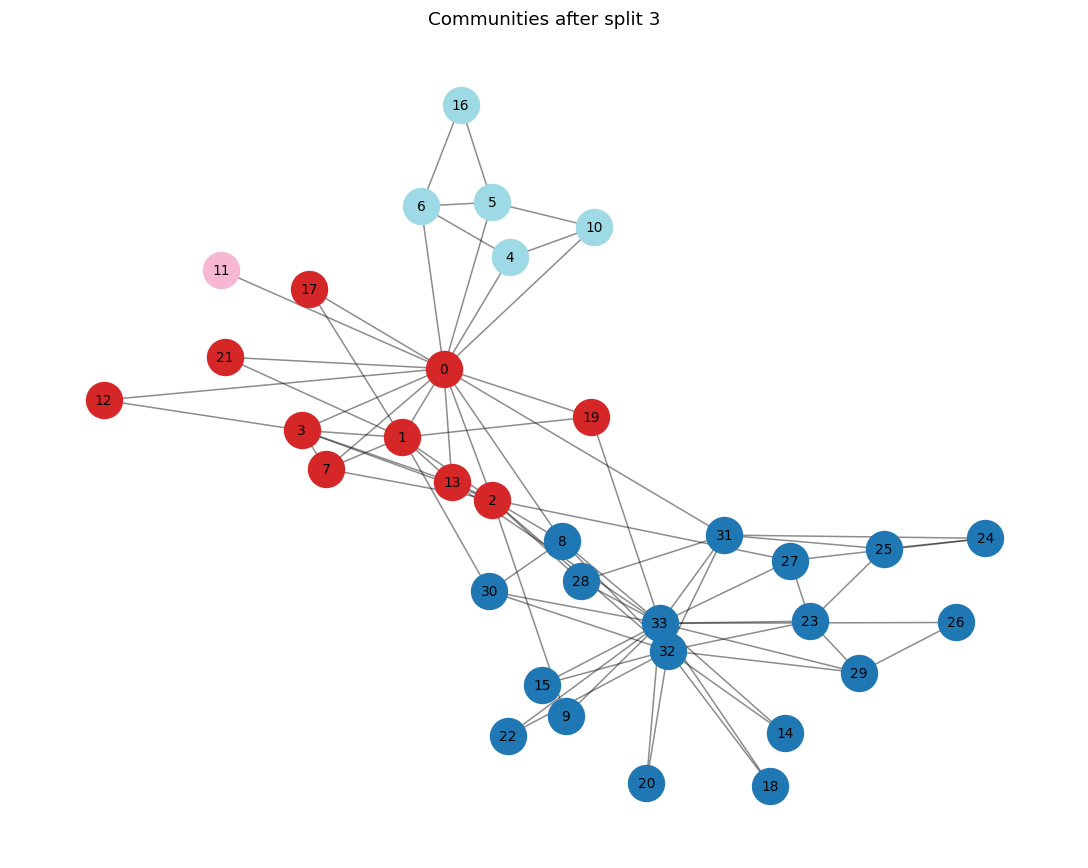

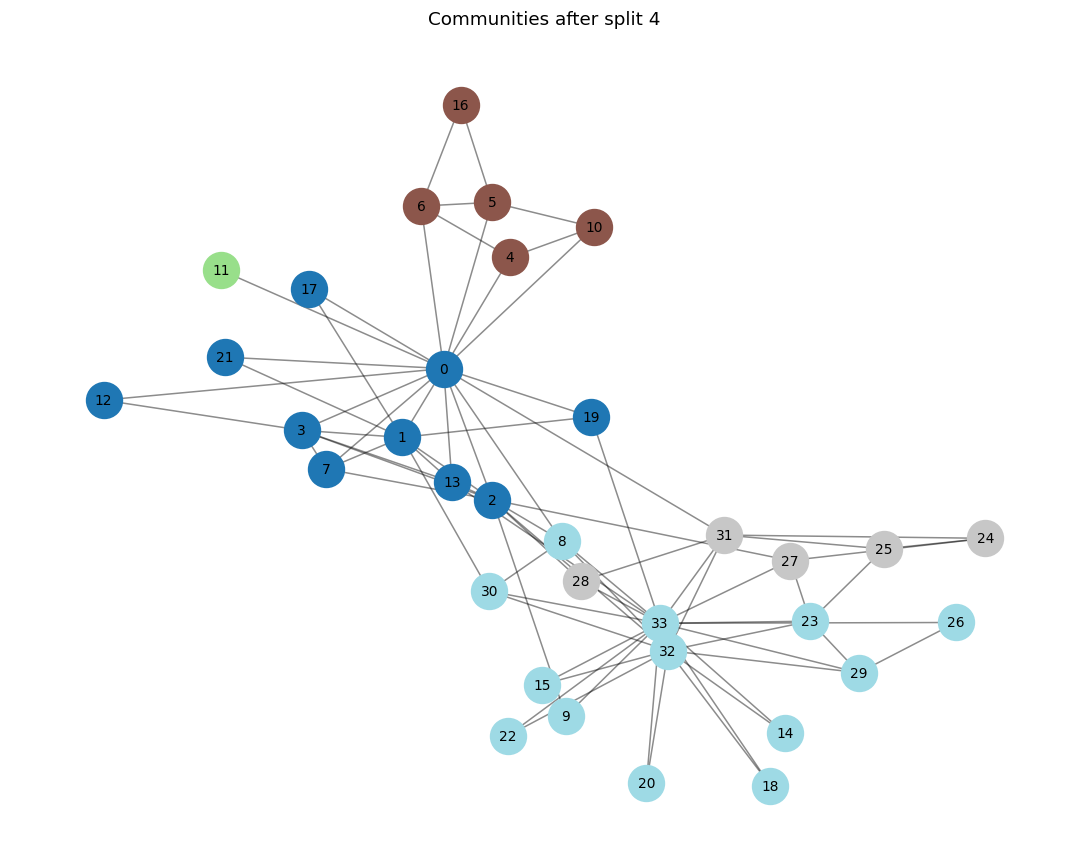

In [6]:
def draw_communities(G, communities, pos, title, filename=None):
    fig, ax = plt.subplots(figsize=(10, 8))
    colors = plt.cm.tab20(np.linspace(0, 1, max(len(communities), 1)))

    for community, color in zip(communities, colors):
        nx.draw_networkx_nodes(
            G, pos,
            nodelist=sorted(community),
            node_color=[color],
            node_size=550,
            ax=ax
        )

    nx.draw_networkx_edges(G, pos, alpha=0.45, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=9, ax=ax)

    ax.set_title(title)
    ax.axis("off")
    fig.tight_layout()

    if filename:
        fig.savefig(filename, dpi=200, bbox_inches="tight")
    plt.show()


for iteration, snapshot in enumerate(snapshots, start=1):
    draw_communities(
        G,
        snapshot["communities"],
        pos,
        f"Communities after split {iteration}",
        os.path.join(COMMUNITY_DIR, f"split_{iteration}.png")
    )

## 7. Calculate node-level network metrics

After each split, we calculate degree centrality, betweenness centrality, closeness centrality, and clustering coefficient for each node.

**Interpretation used here:** each metric is calculated within the node's current community, using the induced subgraph of that community. Consequently, the values can change as the partition becomes finer.

In [7]:
def calculate_metrics(G, communities):
    metrics = {
        "degree": {},
        "betweenness": {},
        "closeness": {},
        "clustering": {}
    }

    for community in communities:
        H = G.subgraph(community)

        degree = nx.degree_centrality(H)
        betweenness = nx.betweenness_centrality(H)
        closeness = nx.closeness_centrality(H)
        clustering = nx.clustering(H)

        for node in community:
            metrics["degree"][node] = degree[node]
            metrics["betweenness"][node] = betweenness[node]
            metrics["closeness"][node] = closeness[node]
            metrics["clustering"][node] = clustering[node]

    return metrics


# Include iteration 0 (the unsplit graph) as a baseline.
metric_history = {
    0: calculate_metrics(G, [set(nodes)])
}

for iteration, snapshot in enumerate(snapshots, start=1):
    metric_history[iteration] = calculate_metrics(G, snapshot["communities"])

print("Metric snapshots recorded:", len(metric_history))
print("Iterations:", list(metric_history.keys()))

Metric snapshots recorded: 5
Iterations: [0, 1, 2, 3, 4]


## 8. Plot the evolution of metrics

Each line represents one node. The x-axis is the partitioning iteration: iteration 0 is the original, unsplit graph; later iterations are the states after successful splits.

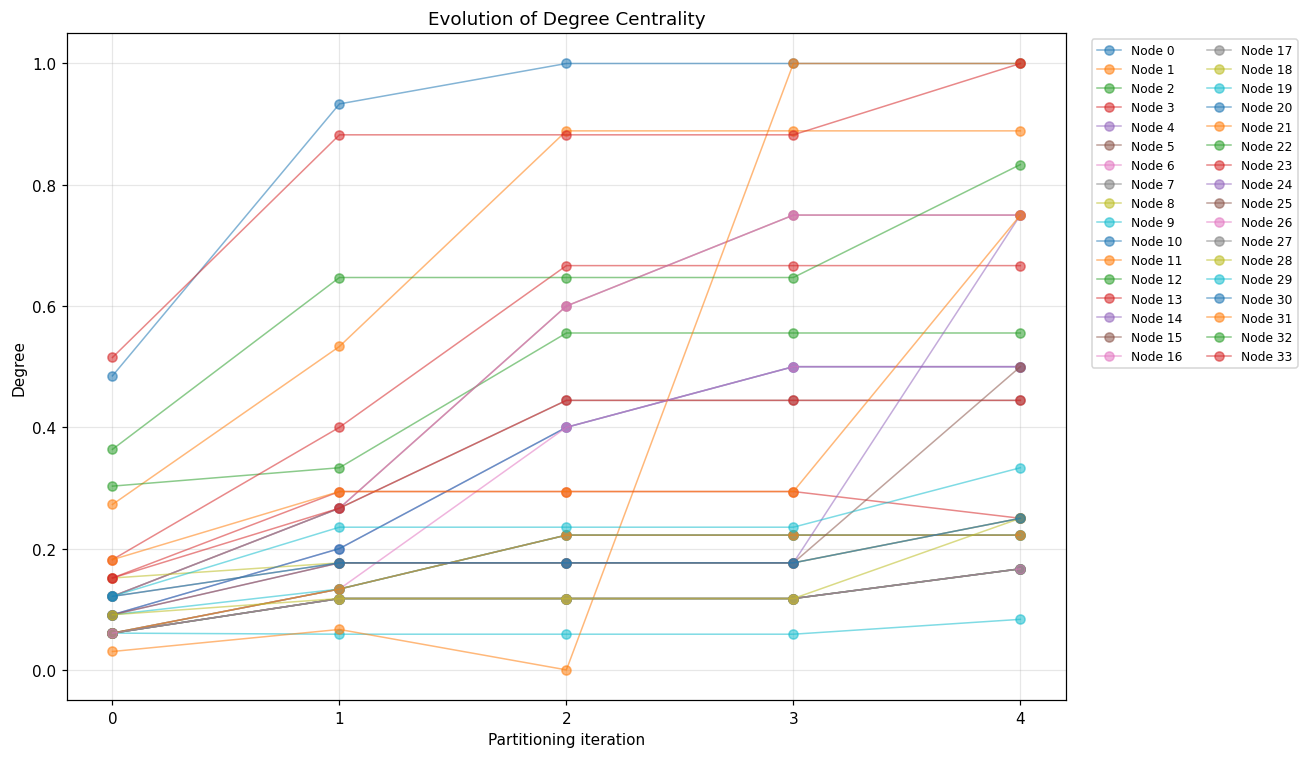

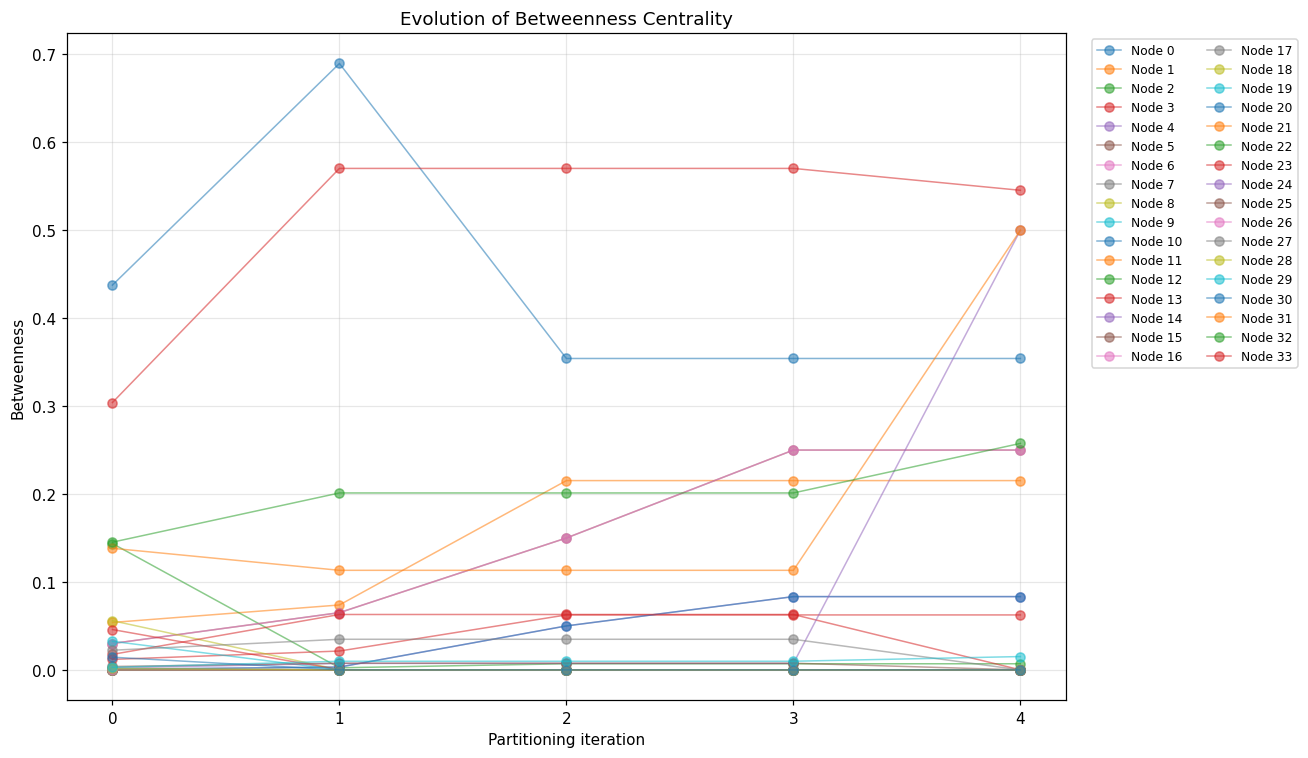

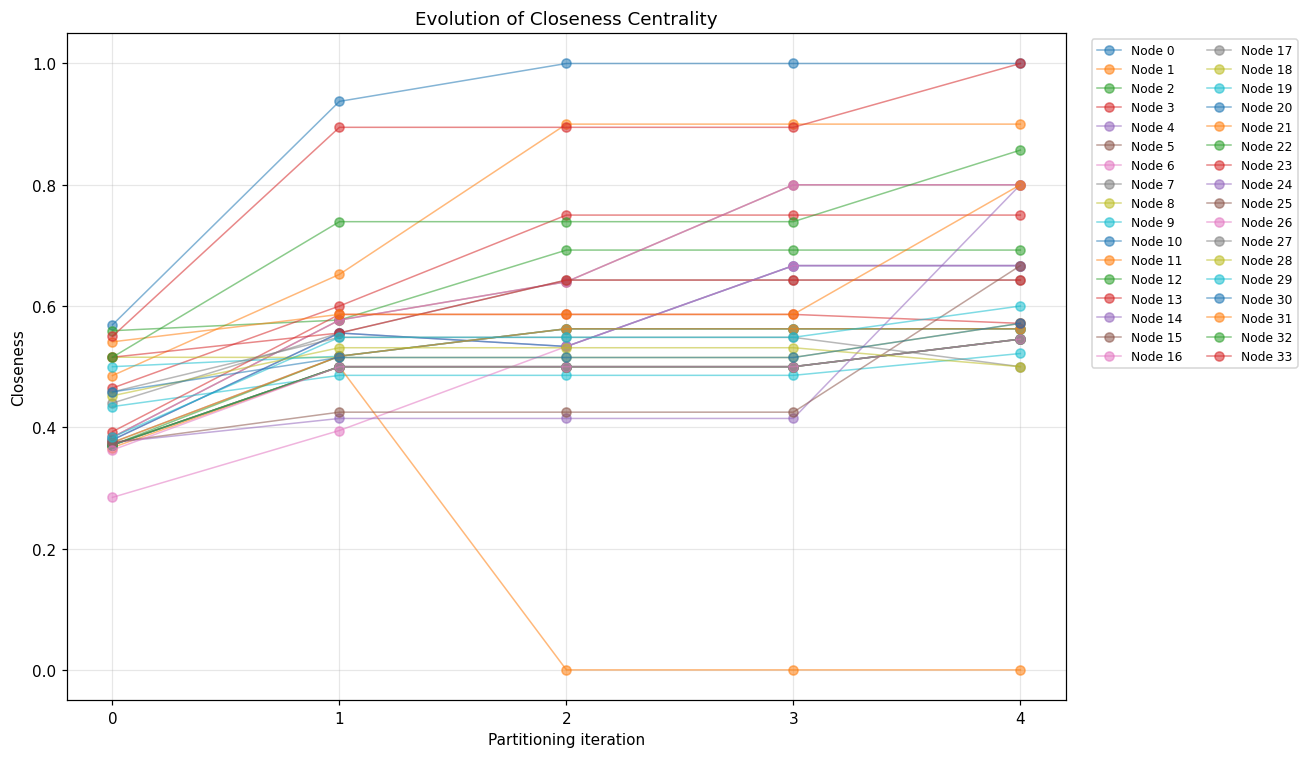

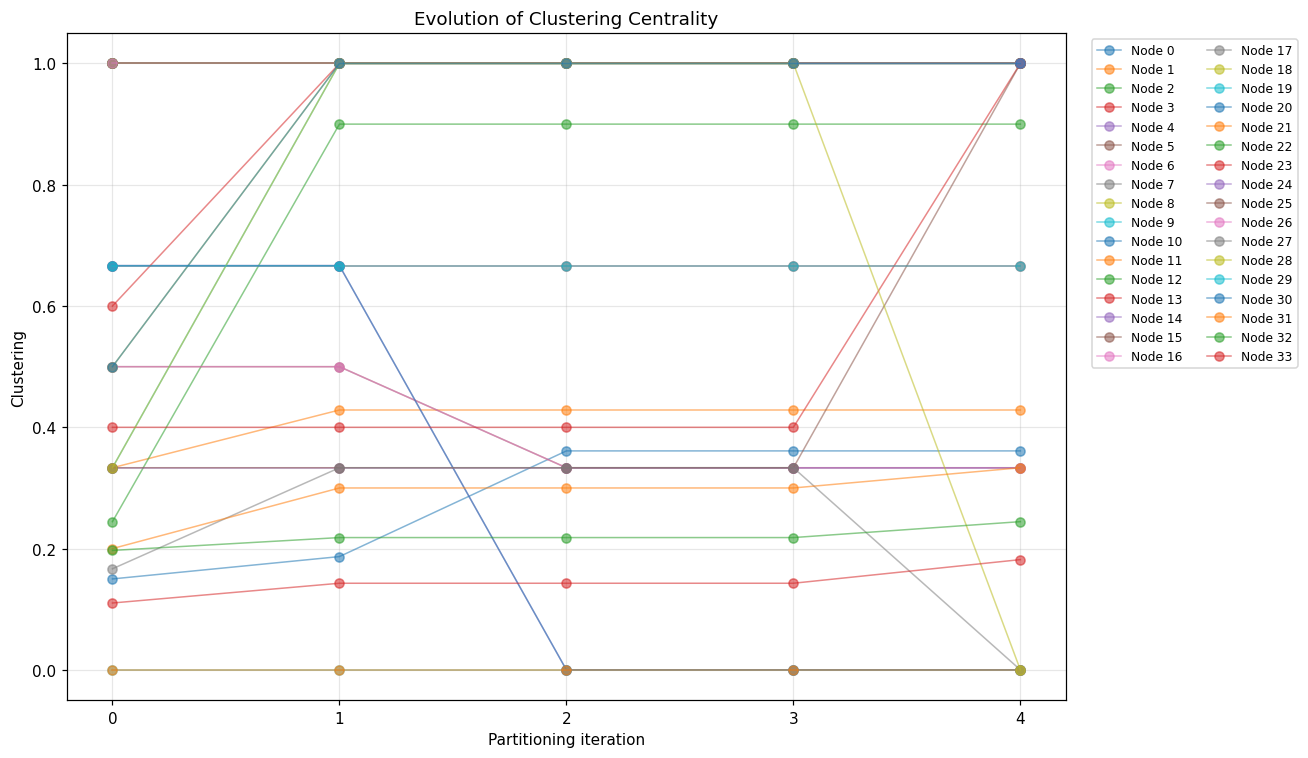

In [8]:
metric_names = ["degree", "betweenness", "closeness", "clustering"]

for metric in metric_names:
    fig, ax = plt.subplots(figsize=(12, 7))

    iterations = list(metric_history.keys())
    for node in nodes:
        values = [metric_history[i][metric][node] for i in iterations]
        ax.plot(
            iterations, values,
            marker="o",
            linewidth=1,
            alpha=0.55,
            label=f"Node {node}"
        )

    ax.set_title(f"Evolution of {metric.capitalize()} Centrality")
    ax.set_xlabel("Partitioning iteration")
    ax.set_ylabel(metric.capitalize())
    ax.set_xticks(iterations)
    ax.grid(alpha=0.3)
    ax.legend(
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        ncol=2,
        fontsize=8
    )
    fig.tight_layout()

    fig.savefig(
        os.path.join(METRIC_DIR, f"{metric}_evolution.png"),
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()

## 9. Save the metric history

The table below stores one row per node per iteration. The CSV is also saved as an output asset.

In [9]:
rows = []

for iteration, metric_data in metric_history.items():
    for node in nodes:
        rows.append({
            "iteration": iteration,
            "node": node,
            "degree": metric_data["degree"][node],
            "betweenness": metric_data["betweenness"][node],
            "closeness": metric_data["closeness"][node],
            "clustering": metric_data["clustering"][node]
        })

metric_df = pd.DataFrame(rows)
csv_path = os.path.join(METRIC_DIR, "metric_history.csv")
metric_df.to_csv(csv_path, index=False)

display(metric_df.head(12))
print(f"Full metric history saved to: {csv_path}")

,iteration,node,degree,betweenness,closeness,clustering
0,0,0,0.484848,0.437635,0.568966,0.150000
1,0,1,0.272727,0.053937,0.485294,0.333333
2,0,2,0.303030,0.143657,0.559322,0.244444
3,0,3,0.181818,0.011909,0.464789,0.666667
4,0,4,0.090909,0.000631,0.379310,0.666667
5,0,5,0.121212,0.029987,0.383721,0.500000
6,0,6,0.121212,0.029987,0.383721,0.500000
7,0,7,0.121212,0.000000,0.440000,1.000000
8,0,8,0.151515,0.055927,0.515625,0.500000
9,0,9,0.060606,0.000848,0.434211,0.000000


Full metric history saved to: output/metrics/metric_history.csv


## 10. Discussion

The recursive spectral partitioning procedure performed four successful splits, resulting in five final communities. The evolution of the network metrics shows how the importance of individual nodes changes as the graph is divided into smaller groups.

**Central nodes across iterations:** Nodes 0 and 33 consistently exhibit high centrality across the partitioning process. In the original graph, node 0 has the highest degree centrality (approximately 0.485) and betweenness centrality (approximately 0.438). Node 33 also has high degree and betweenness centrality. These nodes remain prominent even after several splits, suggesting that they occupy important positions within their respective communities. Node 32 and node 1 also retain relatively high centrality values across multiple iterations.

**Changes in betweenness and closeness:** Nodes 0 and 33 remain particularly important in terms of betweenness centrality, although their values change as the graph is partitioned. In the final iteration, nodes 24 and 31 also exhibit high betweenness within their community. This indicates that their positions become important for connecting other nodes locally. Closeness centrality similarly changes as nodes become restricted to smaller communities. Nodes 0 and 33 remain among the most prominent, while nodes such as 1 and 32 also retain relatively high values.

**Effect of smaller communities on metrics:** As the graph is divided, degree centrality is calculated within each community rather than across the entire original graph. Consequently, a node can have a higher degree centrality after partitioning even though no new edges have been added. This happens because its connections are being compared against a smaller set of possible neighbours. Betweenness and closeness also change because paths are now considered within individual communities. Clustering coefficients tend to be high in tightly connected groups, indicating stronger local connectivity and a greater tendency for neighbouring nodes to be connected to one another.

**Final community structure:** The final partition consists of five communities:
- Community 1: 10 nodes
- Community 2: 1 node
- Community 3: 5 nodes
- Community 4: 5 nodes
- Community 5: 13 nodes

The resulting communities reveal that the original network contains several distinct groups with different internal connectivity patterns. The singleton community containing node 11 is an especially small partition, while the larger communities retain more complex internal structures. Overall, the results demonstrate that spectral partitioning progressively exposes the community structure of the Karate Club graph and that the interpretation of node centrality depends strongly on the network being considered.